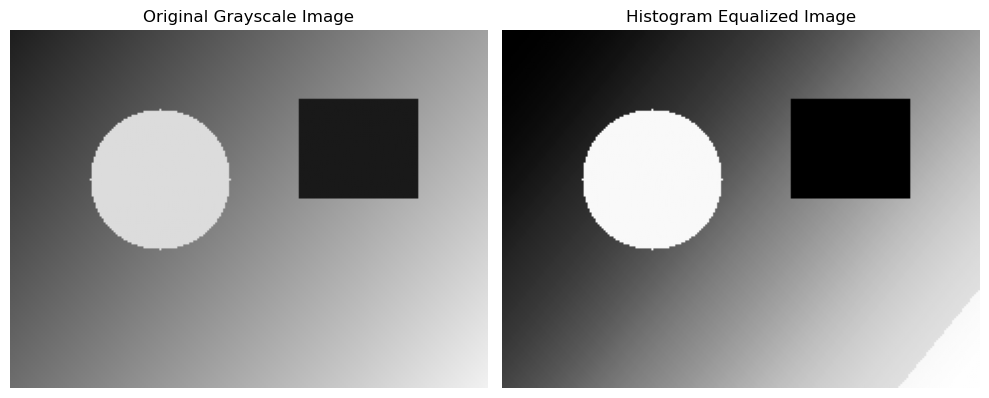

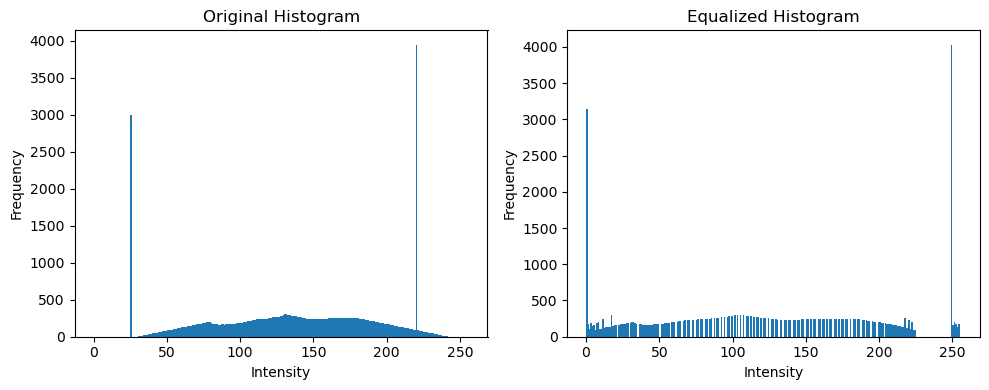

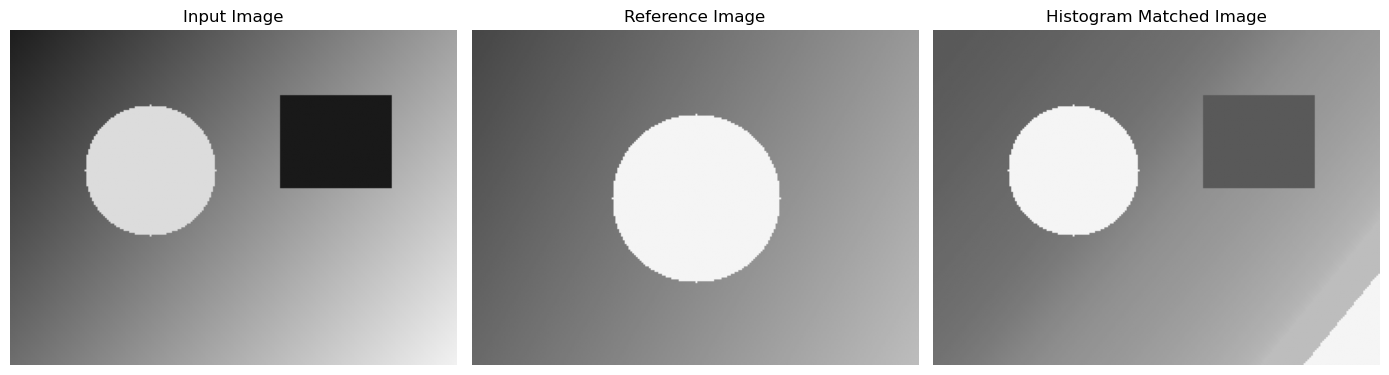

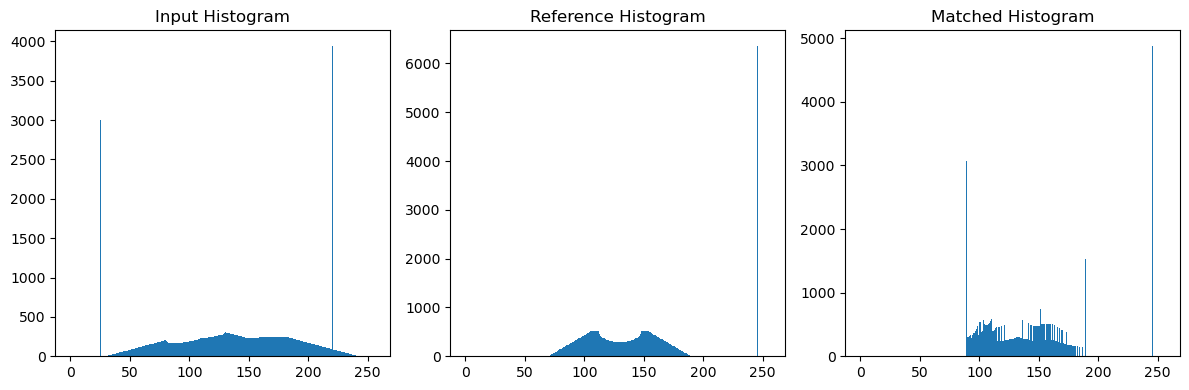

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Generate sample grayscale image
height, width = 180, 240
y, x = np.mgrid[0:height, 0:width]

gray_image = np.clip(30 + 0.55*x + 0.45*y, 0, 255).astype(np.uint8)

yy, xx = np.ogrid[:height, :width]
gray_image[(xx-75)**2 + (yy-75)**2 <= 35**2] = 220
gray_image[35:85, 145:205] = 25


# PART 1: HISTOGRAM EQUALIZATION

histogram = np.bincount(gray_image.ravel(), minlength=256)

cdf = histogram.cumsum()

cdf_normalized = cdf / cdf[-1]

cdf_min = cdf_normalized[np.nonzero(cdf_normalized)][0]

equalization_map = np.clip(
    (cdf_normalized - cdf_min) / (1 - cdf_min) * 255,
    0, 255
).astype(np.uint8)

equalized_image = equalization_map[gray_image]

# Display original and equalized images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap='gray', vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(equalized_image, cmap='gray', vmin=0, vmax=255)
plt.title("Histogram Equalized Image")
plt.axis('off')

plt.tight_layout()
plt.show()

# Display histograms
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(gray_image.ravel(), bins=256, range=(0, 256))
plt.title("Original Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(equalized_image.ravel(), bins=256, range=(0, 256))
plt.title("Equalized Histogram")
plt.xlabel("Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


# PART 2: HISTOGRAM MATCHING

# Generate reference grayscale image
reference_image = np.clip(
    70 + 0.35*x + 0.2*y, 0, 255
).astype(np.uint8)

reference_image[(xx-120)**2 + (yy-90)**2 <= 45**2] = 245

# Calculate histograms
source_hist = np.bincount(
    gray_image.ravel(), minlength=256
)

reference_hist = np.bincount(
    reference_image.ravel(), minlength=256
)

# Calculate CDFs
source_cdf = np.cumsum(source_hist) / source_hist.sum()

reference_cdf = np.cumsum(reference_hist) / reference_hist.sum()

# Create intensity mapping
mapping = np.zeros(256, dtype=np.uint8)

for i in range(256):
    mapping[i] = np.argmin(
        np.abs(reference_cdf - source_cdf[i])
    )

# Apply histogram matching
matched_image = mapping[gray_image]

# Display images
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap='gray', vmin=0, vmax=255)
plt.title("Input Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(reference_image, cmap='gray', vmin=0, vmax=255)
plt.title("Reference Image")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(matched_image, cmap='gray', vmin=0, vmax=255)
plt.title("Histogram Matched Image")
plt.axis('off')

plt.tight_layout()
plt.show()

# Display histogram comparison
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.hist(gray_image.ravel(), bins=256, range=(0, 256))
plt.title("Input Histogram")

plt.subplot(1, 3, 2)
plt.hist(reference_image.ravel(), bins=256, range=(0, 256))
plt.title("Reference Histogram")

plt.subplot(1, 3, 3)
plt.hist(matched_image.ravel(), bins=256, range=(0, 256))
plt.title("Matched Histogram")

plt.tight_layout()
plt.show()